<a href="https://colab.research.google.com/github/fernandinhaalmeida84/Tech_Challenge_Fase_2/blob/main/notebooks/04_Avaliacao_e_Implicacoes_de_Negocio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 4: Avaliação, Importância das Variáveis e Implicações de Negócio**

## Onde estamos na história

No notebook 1 tratamos o cadastro e o histórico de crédito. No notebook 2 definimos o que é inadimplência (**Inad90**, o principal, e **Inad30**, o alternativo). No notebook 3 treinamos dois modelos e vimos, por validação cruzada dentro do treino, que o cadastro prevê **só em parte e de forma fraca**. Deixamos uma parte dos clientes **guardada e intocada**: o conjunto de teste. Chegou a hora de abri-lo, uma única vez, e transformar números em decisão.

## As perguntas que vamos responder

1. **O cadastro prevê inadimplência em clientes que os modelos nunca viram?** O resultado do notebook 3 se confirma, ou era otimismo da validação?
2. **Quais métricas contam a verdade?** O que a acurácia esconde e o que recall, precisão, F1, AUC-PR e AUC-ROC mostram?
3. **Qual nota de corte usar?** Errar para um lado (aprovar um inadimplente) custa diferente de errar para o outro (recusar um bom cliente). Como o resultado muda conforme esse custo?
4. **O que pesa na previsão?** As variáveis que o modelo valoriza fazem sentido de negócio?
5. **Qual modelo levamos e como ele deve ser usado?** Decide sozinho ou ajuda quem decide?

As respostas estão no fim do notebook (seção 11), uma a uma.

## O que fazemos aqui

1. Recriamos os dois modelos com o mesmo código do notebook 3 (cada notebook roda sozinho, sem arquivos intermediários).
2. Avaliamos cada modelo **uma única vez no teste**, nos dois targets, sempre com **faixas de incerteza** (só há 74 inadimplentes no Inad90).
3. Explicamos as métricas e mostramos as matrizes de confusão.
4. Escolhemos a nota de corte **pelo custo de negócio**, como uma **curva de sensibilidade** para várias razões de custo, sem cravar uma razão que não conhecemos. A escolha do corte usa só o treino; o teste apenas confere.
5. Analisamos a **importância das variáveis** (coeficientes e permutação).
6. Escolhemos o modelo, traduzimos tudo para linguagem de negócio e fechamos o projeto com limitações e próximos passos.

## 1. Configuração e leitura das bases

Lemos as duas bases tratadas do notebook 1 direto da pasta `data/`, com `pd.read_csv`. O código procura a pasta a partir de onde o notebook está rodando; se não a encontrar (no Colab, por exemplo), clona o repositório.

Fixamos o `RANDOM_STATE = 42` logo na primeira célula e o usamos em **todos** os pontos aleatórios (divisão, modelos, reamostragens e permutações), para que qualquer pessoa obtenha exatamente os mesmos resultados. Todas as figuras são gravadas também em `results/figures/`, para reaproveitarmos na apresentação.

**Versão do scikit-learn:** os números e os textos deste notebook foram gerados com o **scikit-learn 1.6.1** (a versão do Colab). A divisão por grupos do `StratifiedGroupKFold` muda entre versões da biblioteca, e com ela o conteúdo do teste; por isso a primeira célula avisa se a versão for outra.

In [1]:
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)

URL_REPO = "https://github.com/fernandinhaalmeida84/Tech_Challenge_Fase_2.git"
COR_AZUL, COR_LARANJA, COR_CINZA = "#2F6DB5", "#E07B39", "#8A8F98"


def localizar_data():
    """Acha a pasta data/ (local ou clonada no Colab)."""
    for base_ in (Path.cwd(), Path.cwd().parent):
        for nome in ("data", "Data"):
            if (base_ / nome / "application_record_tratado.csv.gz").exists():
                return base_ / nome
    destino = Path("/content/Tech_Challenge_Fase_2")
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", URL_REPO, str(destino)], check=True)
    return destino / "data"


def br(n):
    """Inteiro com separador de milhar brasileiro."""
    return f"{int(round(n)):,}".replace(",", ".")


def pct(x, casas=2):
    """Proporção como porcentagem brasileira."""
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def num(x, casas=3):
    """Número com vírgula decimal."""
    return f"{x:.{casas}f}".replace(".", ",")


def ic(est, lo, hi, casas=3):
    """Estimativa com a faixa de incerteza (intervalo de 95%)."""
    return f"{num(est, casas)} ({num(lo, casas)} a {num(hi, casas)})"


def ic_pct(est, lo, hi, casas=1):
    return f"{pct(est, casas)} ({pct(lo, casas)} a {pct(hi, casas)})"


DATA_DIR = localizar_data()
ARQ_CADASTRO = DATA_DIR / "application_record_tratado.csv.gz"
ARQ_CREDITO = DATA_DIR / "credit_record_tratado.csv.gz"

# As figuras também são gravadas em results/figures (para a apresentação)
FIG_DIR = DATA_DIR.parent / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")


cadastro = pd.read_csv(ARQ_CADASTRO)
credito = pd.read_csv(ARQ_CREDITO, dtype={"STATUS": str})

import sklearn, warnings
warnings.filterwarnings("ignore", message="Unknown solver options")
VERSAO_ESPERADA = "1.6.1"   # a divisão treino/teste do StratifiedGroupKFold muda entre versões do scikit-learn
print(f"scikit-learn {sklearn.__version__}" + ("" if sklearn.__version__ == VERSAO_ESPERADA else
      f" (ATENÇÃO: os números do texto foram gerados com a versão {VERSAO_ESPERADA}; com outra versão a divisão e os resultados mudam)"))
print("Pasta de dados:", DATA_DIR.name)
print(f"Cadastro: {br(cadastro.shape[0])} linhas x {cadastro.shape[1]} colunas")
print(f"Histórico: {br(credito.shape[0])} linhas x {credito.shape[1]} colunas")


scikit-learn 1.6.1
Pasta de dados: data
Cadastro: 438.463 linhas x 22 colunas
Histórico: 1.048.575 linhas x 3 colunas


## 2. Refazendo a junção e os targets

Repetimos o código do notebook 3 (seção 2): marcamos, para cada cliente, se **em algum mês** o `STATUS` caiu na regra do Inad90 ou do Inad30 e juntamos ao cadastro pelo `ID` com junção **interna**. Repetir o código, em vez de gravar uma base intermediária, foi uma escolha consciente: cada notebook roda sozinho e a regra do target fica em um único lugar.

Incluímos conferências automáticas (`assert`): se algum número não bater com o notebook anterior, o código para em vez de seguir com uma base diferente.

In [2]:
STATUS_INAD30 = ["1", "2", "3", "4", "5"]   # atraso a partir de 30 dias
STATUS_INAD90 = ["3", "4", "5"]             # atraso a partir de 90 dias

marcas = credito.assign(
    ATRASO_30=credito["STATUS"].isin(STATUS_INAD30),
    ATRASO_90=credito["STATUS"].isin(STATUS_INAD90),
)
alvo = (
    marcas.groupby("ID")
    .agg(
        Inad90=("ATRASO_90", "max"),
        Inad30=("ATRASO_30", "max"),
        MESES_HISTORICO=("MONTHS_BALANCE", "nunique"),
    )
    .reset_index()
)
alvo[["Inad90", "Inad30"]] = alvo[["Inad90", "Inad30"]].astype(int)

base = cadastro.merge(alvo, on="ID", how="inner", validate="one_to_one")

assert base["ID"].is_unique
assert (base["Inad90"] <= base["Inad30"]).all(), "Inad90 não pode existir sem Inad30"
assert (len(base), base["Inad90"].sum(), base["Inad30"].sum()) == (36457, 302, 4291), "A base não bate com o notebook 2"

resumo = pd.DataFrame({
    "Target": ["Inad90 (principal)", "Inad30 (alternativo)"],
    "Inadimplentes": [base["Inad90"].sum(), base["Inad30"].sum()],
    "Clientes": [len(base)] * 2,
})
resumo["Taxa"] = (resumo["Inadimplentes"] / resumo["Clientes"]).map(pct)
resumo["Inadimplentes"] = resumo["Inadimplentes"].map(br)
resumo["Clientes"] = resumo["Clientes"].map(br)

print(f"Clientes com cadastro e histórico: {br(len(base))} ({pct(len(base) / len(cadastro))} do cadastro)")
display(resumo)


Clientes com cadastro e histórico: 36.457 (8,31% do cadastro)


,Target,Inadimplentes,Clientes,Taxa
0,Inad90 (principal),302,36.457,"0,83%"
1,Inad30 (alternativo),4.291,36.457,"11,77%"


**Leitura:** os números batem com os dos notebooks 2 e 3: **36.457 clientes** (8,31% do cadastro, a única parte em que dá para medir inadimplência), com **302 inadimplentes no Inad90 (0,83%)** e **4.291 no Inad30 (11,77%)**. O Inad90 é uma classe muito rara, e isso orienta a escolha das métricas mais adiante.

## 3. As mesmas variáveis e a mesma divisão do notebook 3

Aplicamos as decisões já tomadas: descartamos `ID`, os targets, `MESES_HISTORICO` (vazamento: só existe depois da aprovação), `FLAG_MOBIL` (constante), `PERFIL_ID` (usado só para agrupar) e as colunas `DAYS_BIRTH` e `DAYS_EMPLOYED` (já representadas por `Idade`, `Anos_Trabalhados` e `Desempregado ou aposentado`). Ficamos com **17 variáveis do cliente**.

Repetimos também a divisão **por perfil**, estratificada pelo Inad90, com a mesma semente e a mesma versão da biblioteca: a primeira das 5 dobras (cerca de 20%) é o teste. O código é o mesmo do notebook 3, então o teste é **o mesmo** que ele deixou guardado.

In [3]:
DESCARTAR = {
    "ID": "Identificador do cliente, não descreve ninguém.",
    "Inad90": "É o target.",
    "Inad30": "É o target alternativo.",
    "MESES_HISTORICO": "Vazamento: só existe depois da aprovação e cresce junto com a inadimplência (efeito de exposição).",
    "FLAG_MOBIL": "Constante: vale 1 para todos os clientes.",
    "PERFIL_ID": "Usado só para dividir por grupo, nunca como variável.",
    "DAYS_BIRTH": "Já representada por Idade.",
    "DAYS_EMPLOYED": "Já representada por Anos_Trabalhados e Desempregado ou aposentado.",
}

X = base.drop(columns=list(DESCARTAR)).copy()
X["Desempregado ou aposentado"] = X["Desempregado ou aposentado"].astype(int)   # True/False -> 1/0

alvos = {"Inad90": base["Inad90"], "Inad30": base["Inad30"]}
grupos = base["PERFIL_ID"]
colunas_cat = X.select_dtypes(exclude="number").columns.tolist()
print(f"Variáveis do modelo: {X.shape[1]} ({len(colunas_cat)} categóricas e {X.shape[1] - len(colunas_cat)} numéricas)")

# Mesma divisão do notebook 3: por perfil, estratificada pelo Inad90, primeira dobra (~20%) como teste
from sklearn.model_selection import StratifiedGroupKFold

divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(divisor.split(X, alvos["Inad90"], grupos))

X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
g_treino, g_teste = grupos.iloc[idx_treino], grupos.iloc[idx_teste]
y_treino = {nome: y.iloc[idx_treino] for nome, y in alvos.items()}
y_teste = {nome: y.iloc[idx_teste] for nome, y in alvos.items()}

assert set(g_treino).isdisjoint(set(g_teste)), "Perfil vazou entre treino e teste"



def linha(nome, Xp, gp, yp):
    return {
        "Conjunto": nome,
        "Clientes": br(len(Xp)),
        "Perfis distintos": br(gp.nunique()),
        "Inad90 (casos)": br(yp["Inad90"].sum()),
        "Inad90 (taxa)": pct(yp["Inad90"].mean()),
        "Inad30 (casos)": br(yp["Inad30"].sum()),
        "Inad30 (taxa)": pct(yp["Inad30"].mean()),
    }


display(pd.DataFrame([
    linha("Treino", X_treino, g_treino, y_treino),
    linha("Teste", X_teste, g_teste, y_teste),
]))
print("Checagem ok: nenhum perfil aparece ao mesmo tempo no treino e no teste.")


Variáveis do modelo: 17 (8 categóricas e 9 numéricas)


,Conjunto,Clientes,Perfis distintos,Inad90 (casos),Inad90 (taxa),Inad30 (casos),Inad30 (taxa)
0,Treino,29.370,7.788,228,"0,78%",3.484,"11,86%"
1,Teste,7.087,1.940,74,"1,04%",807,"11,39%"


Checagem ok: nenhum perfil aparece ao mesmo tempo no treino e no teste.


**Leitura:** o treino tem **29.370 clientes (228 inadimplentes no Inad90 e 3.484 no Inad30)** e o teste, **7.087 clientes (74 no Inad90 e 807 no Inad30)**. As taxas ficaram próximas, mas não iguais: **0,78% de Inad90 no treino contra 1,04% no teste** (e 11,86% contra 11,39% no Inad30). Com tão poucos casos raros, a estratificação por perfil não consegue igualar as taxas por completo, e isso importa: o teste tem uma taxa de base um pouco mais alta, então comparamos sempre com o baseline do próprio teste. Nenhum perfil aparece nos dois conjuntos. Esses 74 inadimplentes continuam sendo o gargalo da avaliação, e por isso todos os resultados vêm com faixa de incerteza.

## 4. Recriando o pré-processamento e os modelos

Repetimos o `Pipeline` do notebook 3: winsorização de `Anos_Trabalhados`, teto de 5 em `CNT_FAM_MEMBERS`, `log1p` na renda, *one-hot* com categorias raras (menos de 1% do treino) agrupadas e normalização só para a Regressão Logística. Tudo é aprendido **apenas com o treino**.

Não refazemos a busca de hiperparâmetros: **congelamos** os valores que o notebook 3 escolheu por validação cruzada (maior AUC-PR) e treinamos os quatro modelos (2 algoritmos × 2 targets) com o treino inteiro. Isso mantém o teste fora de qualquer decisão de ajuste e ainda deixa o notebook rápido.

- **Regressão Logística:** `class_weight="balanced"`, `C=1` nos dois targets.
- **Random Forest:** 150 árvores, `class_weight="balanced_subsample"`; Inad90 com `max_depth=None` e `min_samples_leaf=10`; Inad30 com `max_depth=8` e `min_samples_leaf=30`.

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


class Winsorizador(BaseEstimator, TransformerMixin):
    """Limita o valor máximo a Q3 + 1,5 x IQR, com o limite aprendido só no treino."""

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        self.limite_ = q3 + 1.5 * (q3 - q1)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.limite_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def limitar_em_5(a):
    return np.minimum(a, 5)


def montar_preprocessador(escalar):
    """Pré-processamento do notebook 3. `escalar=True` acrescenta a normalização (modelos lineares)."""

    def etapas(*passos):
        passos = list(passos)
        if escalar:
            passos.append(("escala", StandardScaler()))
        return Pipeline(passos)

    return ColumnTransformer(
        [
            ("anos", etapas(("winsor", Winsorizador())), ["Anos_Trabalhados"]),
            ("familia", etapas(("teto", FunctionTransformer(limitar_em_5, feature_names_out="one-to-one"))), ["CNT_FAM_MEMBERS"]),
            ("renda", etapas(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))), ["AMT_INCOME_TOTAL"]),
            ("numericas", StandardScaler() if escalar else "passthrough", ["Idade", "CNT_CHILDREN"]),
            ("binarias", "passthrough", ["FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "Desempregado ou aposentado"]),
            ("categoricas", OneHotEncoder(drop="if_binary", min_frequency=0.01,
                                          handle_unknown="infrequent_if_exist", sparse_output=False), colunas_cat),
        ],
        verbose_feature_names_out=False,
    )


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

MODELOS = ["Regressão Logística", "Random Forest"]

# Hiperparâmetros escolhidos por validação cruzada (por AUC-PR) no notebook 3
HIPERPARAMETROS = {
    "Inad90": {"Regressão Logística": {"C": 1},
               "Random Forest": {"max_depth": None, "min_samples_leaf": 10}},
    "Inad30": {"Regressão Logística": {"C": 1},
               "Random Forest": {"max_depth": 8, "min_samples_leaf": 30}},
}


def montar_modelo(nome, alvo_nome):
    """Pipeline completo (pré-processamento + modelo) com os hiperparâmetros do notebook 3."""
    hp = HIPERPARAMETROS[alvo_nome][nome]
    if nome == "Regressão Logística":
        return Pipeline([("prep", montar_preprocessador(True)),
                         ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000,
                                                       random_state=RANDOM_STATE, **hp))])
    return Pipeline([("prep", montar_preprocessador(False)),
                     ("modelo", RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample",
                                                       random_state=RANDOM_STATE, n_jobs=-1, **hp))])


# Treinados SÓ com o treino. O teste não entra em nenhuma decisão de ajuste.
modelos_finais = {(a, n): montar_modelo(n, a).fit(X_treino, y_treino[a]) for a in alvos for n in MODELOS}

display(pd.DataFrame([
    {"Target": a, "Modelo": n, "Hiperparâmetros": ", ".join(f"{k}={v}" for k, v in HIPERPARAMETROS[a][n].items())}
    for a in alvos for n in MODELOS
]))
print("Quatro modelos treinados (2 algoritmos x 2 targets), todos só com o treino.")


,Target,Modelo,Hiperparâmetros
0,Inad90,Regressão Logística,C=1
1,Inad90,Random Forest,"max_depth=None, min_samples_leaf=10"
2,Inad30,Regressão Logística,C=1
3,Inad30,Random Forest,"max_depth=8, min_samples_leaf=30"


Quatro modelos treinados (2 algoritmos x 2 targets), todos só com o treino.


**Leitura:** os quatro modelos estão prontos e **nenhum viu o teste**. Daqui para a frente, o teste só é usado para **medir** (nunca para escolher hiperparâmetros, variáveis ou notas de corte).

## 5. Pergunta 1: o cadastro prevê inadimplência em clientes novos?

Pedimos a cada modelo a probabilidade de inadimplência de cada um dos 7.087 clientes do teste e medimos duas notas que **não dependem de nota de corte**:

- **AUC-ROC:** capacidade de **ordenar** os clientes do menos para o mais arriscado. Vale 0,5 para um sorteio e 1 para uma ordenação perfeita.
- **AUC-PR:** equilíbrio entre pegar inadimplentes e não gerar alarmes falsos, olhando só a classe rara. A referência (baseline) é a própria taxa de inadimplentes: um modelo sem poder preditivo fica nesse patamar.

**Como medimos a incerteza:** com apenas 74 inadimplentes, um número único engana. Fizemos um ***bootstrap por perfil***: sorteamos perfis inteiros (com reposição), recalculamos a métrica e repetimos **1.000 vezes**. Sortear perfis, e não clientes soltos, respeita o agrupamento do notebook 3: clientes do mesmo perfil não são independentes, e tratá-los como se fossem faria a faixa parecer mais estreita do que é. Mostramos o valor observado e a **faixa de 95%** das reamostragens.

In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Uma única passada no teste: probabilidades previstas para os clientes que os modelos nunca viram
prob_teste = {(a, n): modelos_finais[(a, n)].predict_proba(X_teste)[:, 1] for a in alvos for n in MODELOS}

# Bootstrap POR PERFIL: sorteamos perfis inteiros (com reposição) e cada cliente herda o peso do seu perfil
N_BOOT = 1000
codigos, _ = pd.factorize(g_teste)
n_perfis = codigos.max() + 1
rng = np.random.default_rng(RANDOM_STATE)
PESOS = np.stack([np.bincount(rng.integers(0, n_perfis, n_perfis), minlength=n_perfis)[codigos] for _ in range(N_BOOT)]).astype(float)
PESOS_UNIT = np.ones((1, len(X_teste)))   # "reamostragem" única com peso 1 = resultado observado


def auc_pr_pond(y, s, w):
    m = w > 0
    return average_precision_score(y[m], s[m], sample_weight=w[m])


def auc_roc_pond(y, s, w):
    m = w > 0
    return roc_auc_score(y[m], s[m], sample_weight=w[m])


auc = {}   # auc[(alvo, modelo)] = {"AUC-PR": (observado, reamostragens), "AUC-ROC": (...)}
for a in alvos:
    y = y_teste[a].to_numpy()
    for n in MODELOS:
        s = prob_teste[(a, n)]
        auc[(a, n)] = {
            "AUC-PR": (auc_pr_pond(y, s, PESOS_UNIT[0]), np.array([auc_pr_pond(y, s, w) for w in PESOS])),
            "AUC-ROC": (auc_roc_pond(y, s, PESOS_UNIT[0]), np.array([auc_roc_pond(y, s, w) for w in PESOS])),
        }

linhas = []
for a in alvos:
    prevalencia = y_teste[a].mean()
    linhas.append({"Target": a, "Modelo": "Baseline (taxa média)", "AUC-PR": num(prevalencia), "AUC-ROC": num(0.5)})
    for n in MODELOS:
        reg = {"Target": a, "Modelo": n}
        for metrica in ("AUC-PR", "AUC-ROC"):
            obs, boot = auc[(a, n)][metrica]
            lo, hi = np.percentile(boot, [2.5, 97.5])
            reg[metrica] = ic(obs, lo, hi)
        # Em quantas reamostragens a AUC-ROC não passa do sorteio (0,5)?
        reg["Reamostragens com AUC-ROC <= 0,5"] = pct((auc[(a, n)]["AUC-ROC"][1] <= 0.5).mean(), 1)
        linhas.append(reg)

print(f"Avaliação única no teste: {br(len(X_teste))} clientes, {N_BOOT} reamostragens por perfil. Valor observado (faixa de 95%).")
display(pd.DataFrame(linhas).fillna("-"))


Avaliação única no teste: 7.087 clientes, 1000 reamostragens por perfil. Valor observado (faixa de 95%).


,Target,Modelo,AUC-PR,AUC-ROC,"Reamostragens com AUC-ROC <= 0,5"
0,Inad90,Baseline (taxa média),"0,010","0,500",-
1,Inad90,Regressão Logística,"0,039 (0,018 a 0,088)","0,599 (0,502 a 0,692)","2,1%"
2,Inad90,Random Forest,"0,043 (0,016 a 0,097)","0,577 (0,468 a 0,684)","8,0%"
3,Inad30,Baseline (taxa média),"0,114","0,500",-
4,Inad30,Regressão Logística,"0,142 (0,122 a 0,173)","0,554 (0,519 a 0,586)","0,0%"
5,Inad30,Random Forest,"0,134 (0,118 a 0,159)","0,545 (0,511 a 0,579)","0,5%"


**Leitura da tabela:**

- **Inad90 (principal):** a AUC-ROC no teste é de **0,599 (Regressão Logística) e 0,577 (Random Forest)**. Há um sinal, mas **fraco**. A faixa da Regressão Logística (0,502 a 0,692) fica por pouco acima do sorteio (em 2,1% das reamostragens ela não passa de 0,5); a do Random Forest (0,468 a 0,684) **inclui o sorteio** (8,0% das reamostragens). O AUC-PR é de **0,039 e 0,043** contra um baseline de 0,010, cerca de 4 vezes melhor que ignorar o perfil e com faixas (0,018 a 0,088 e 0,016 a 0,097) acima do baseline, mas em um patamar absoluto muito baixo.
- **Inad30 (alternativo):** com 807 casos as faixas são estreitas e o resultado é mais confiável: AUC-ROC de **0,554 e 0,545**, ambas detectavelmente acima do sorteio, mas por uma margem pequena; AUC-PR de 0,142 e 0,134 contra 0,114 do baseline. É um sinal quase sem valor prático.
- **Os dois modelos continuam empatados:** a diferença entre eles é pequena diante das faixas.

O resultado é **coerente com o notebook 3**: sinal fraco no atraso grave e ainda mais fraco no atraso leve.

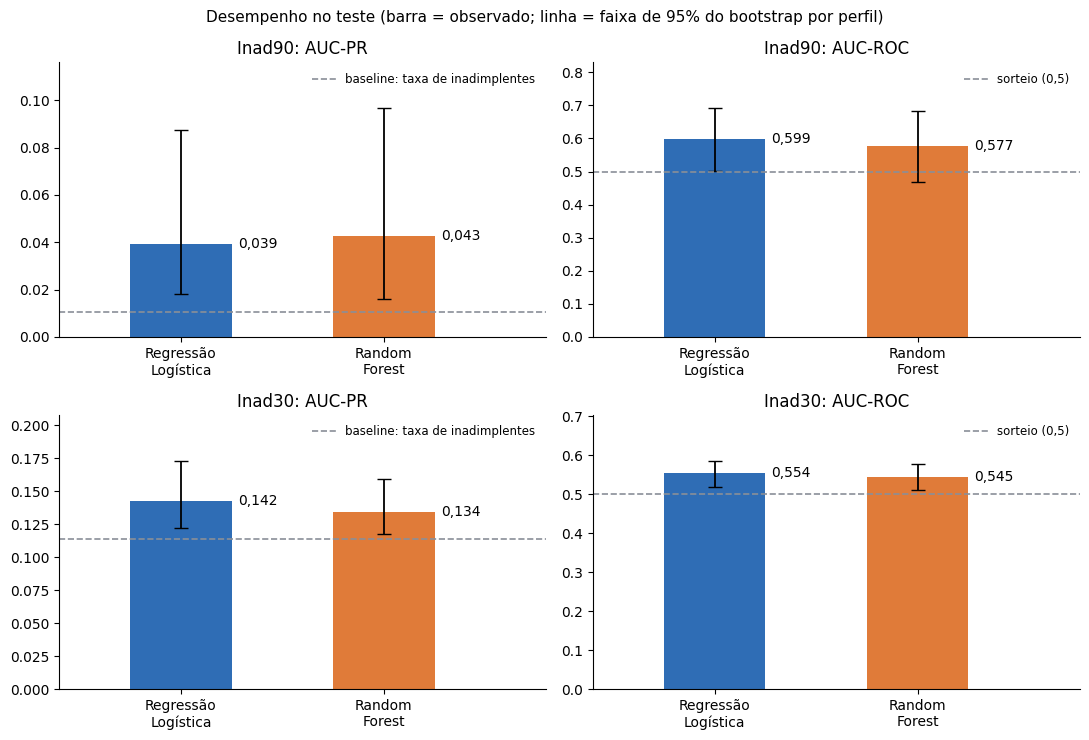

In [7]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 7.5))
cores = [COR_AZUL, COR_LARANJA]

for i, a in enumerate(alvos):
    for j, (metrica, ref, rotulo_ref) in enumerate([
        ("AUC-PR", y_teste[a].mean(), "baseline: taxa de inadimplentes"),
        ("AUC-ROC", 0.5, "sorteio (0,5)"),
    ]):
        ax = eixos[i, j]
        topo = 0
        for k, n in enumerate(MODELOS):
            obs, boot = auc[(a, n)][metrica]
            lo, hi = np.percentile(boot, [2.5, 97.5])
            ax.bar(k, obs, color=cores[k], width=0.5)
            ax.errorbar(k, obs, yerr=[[obs - lo], [hi - obs]], color="black", capsize=5, linewidth=1.3)
            ax.text(k + 0.28, obs, num(obs), va="center", fontsize=10)
            topo = max(topo, hi)
        ax.axhline(ref, color=COR_CINZA, linestyle="--", linewidth=1.2, label=rotulo_ref)
        ax.set_ylim(0, max(topo, ref) * 1.2)
        ax.legend(frameon=False, loc="upper right", fontsize=8.5)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Regressão\nLogística", "Random\nForest"])
        ax.set_title(f"{a}: {metrica}")
        ax.set_xlim(-0.6, 1.8)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Desempenho no teste (barra = observado; linha = faixa de 95% do bootstrap por perfil)", fontsize=11)
plt.tight_layout()
salvar(fig, "04_desempenho_teste")
plt.show()


**Leitura do gráfico:** as barras são o valor observado no teste e as linhas pretas, a faixa de 95%. A linha cinza tracejada é a referência (taxa de inadimplentes no AUC-PR e 0,5 na AUC-ROC). No Inad90, as barras do AUC-PR ficam bem acima da referência, mas as linhas pretas são longas; na AUC-ROC, a faixa da Regressão Logística apenas encosta no 0,5 e a do Random Forest o atravessa: com 74 inadimplentes, **o sinal existe, mas não podemos afirmar que seja grande**. No Inad30 as linhas são curtas e as barras ficam pouco acima da referência. Resumindo: **o teste confirma o notebook 3, com um sinal fraco no atraso grave e muito fraco no leve**.

## 6. Pergunta 2: quais métricas contam a verdade?

| Métrica | O que responde | Por que importa aqui |
|---|---|---|
| **Acurácia** | De todos os clientes, quantos o modelo acertou | **Engana**: no Inad90, "aprovar todo mundo" acerta 98,96% sem prever nada |
| **Recall** | Dos inadimplentes reais, quantos o modelo pegou | É o custo de **deixar passar** um mau pagador |
| **Precisão** | Dos clientes apontados como risco, quantos realmente eram | É o custo de **recusar um bom cliente** |
| **F1** | Resume recall e precisão em um número | Útil para comparar, mas esconde qual dos dois erros pesa mais |
| **AUC-PR** | Qualidade da ordenação olhando só a classe rara | Mais honesta que a AUC-ROC quando a classe é muito rara |
| **AUC-ROC** | Capacidade de ordenar bons e maus pagadores | Não depende da nota de corte |
| **Matriz de confusão** | Os quatro tipos de acerto e erro, em contagens | Mostra, em clientes de verdade, o que cada erro significa |

Recall, precisão, F1 e a matriz dependem de uma **nota de corte**. Aqui usamos o corte padrão de **0,5**, o mesmo do notebook 3, só para comparar. A escolha do corte com critério de negócio vem na seção 7. Incluímos a acurácia nesta tabela de propósito, para mostrar o problema, e adicionamos a linha "aprova todos" (um baseline que nunca aponta ninguém).

In [8]:
def contagens(pred, y, pesos):
    """Verdadeiros/falsos positivos e negativos, ponderados (uma linha de `pesos` = uma reamostragem)."""
    pred = np.asarray(pred, dtype=bool)
    pos = np.asarray(y) == 1
    tp = pesos @ (pred & pos)
    fp = pesos @ (pred & ~pos)
    p = pesos @ pos
    n = pesos.sum(axis=1)
    return {"tp": tp, "fp": fp, "fn": p - tp, "tn": n - p - fp, "pos": p, "n": n}


def divide(a, b):
    return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b > 0)


def derivadas(c):
    recall = divide(c["tp"], c["pos"])
    precisao = divide(c["tp"], c["tp"] + c["fp"])
    f1 = divide(2 * precisao * recall, precisao + recall)
    acuracia = (c["tp"] + c["tn"]) / c["n"]
    return {"Acurácia": acuracia, "Recall": recall, "Precisão": precisao, "F1": f1}


def faixa95(boot):
    return np.percentile(boot, [2.5, 97.5])


CORTE_PADRAO = 0.5   # o mesmo corte do notebook 3, só para comparar
linhas = []
for a in alvos:
    y = y_teste[a].to_numpy()
    # baseline "aprovar todos": nunca aponta ninguém
    c0 = contagens(np.zeros(len(y)), y, PESOS_UNIT)
    linhas.append({"Target": a, "Modelo": "Aprova todos (baseline)",
                   "Acurácia": pct(derivadas(c0)["Acurácia"][0]), "Recall": "0,0%", "Precisão": "0,0%", "F1": num(0, 3)})
    for n in MODELOS:
        pred = prob_teste[(a, n)] >= CORTE_PADRAO
        obs = derivadas(contagens(pred, y, PESOS_UNIT))
        boot = derivadas(contagens(pred, y, PESOS))
        reg = {"Target": a, "Modelo": n}
        for m in ("Acurácia", "Recall", "Precisão"):
            reg[m] = ic_pct(obs[m][0], *faixa95(boot[m]))
        reg["F1"] = ic(obs["F1"][0], *faixa95(boot["F1"]))
        linhas.append(reg)

print(f"Métricas no teste com o corte padrão de {num(CORTE_PADRAO, 1)} (observado e faixa de 95%):")
display(pd.DataFrame(linhas))


Métricas no teste com o corte padrão de 0,5 (observado e faixa de 95%):


,Target,Modelo,Acurácia,Recall,Precisão,F1
0,Inad90,Aprova todos (baseline),"98,96%","0,0%","0,0%","0,000"
1,Inad90,Regressão Logística,"64,6% (61,7% a 67,3%)","41,9% (26,6% a 58,0%)","1,2% (0,7% a 1,9%)","0,024 (0,013 a 0,036)"
2,Inad90,Random Forest,"98,9% (98,5% a 99,2%)","4,1% (0,0% a 9,5%)","23,1% (0,0% a 100,0%)","0,069 (0,000 a 0,146)"
3,Inad30,Aprova todos (baseline),"88,61%","0,0%","0,0%","0,000"
4,Inad30,Regressão Logística,"54,8% (52,2% a 57,4%)","49,2% (43,4% a 55,5%)","12,4% (10,9% a 14,2%)","0,199 (0,176 a 0,223)"
5,Inad30,Random Forest,"64,4% (61,8% a 67,0%)","37,8% (32,2% a 43,6%)","13,1% (11,2% a 15,3%)","0,195 (0,167 a 0,224)"


**Leitura da tabela:**

- **A acurácia é enganosa.** No Inad90, o Random Forest "ganha" com 98,9% de acurácia, mas só pega **3 dos 74 inadimplentes** (recall de 4,1%), e ainda fica abaixo do baseline "aprova todos" (98,96%), que não prevê nada. A Regressão Logística tem acurácia de apenas 64,6% e pega 31 dos 74: parece "pior" justamente porque faz o trabalho de apontar risco.
- **Regressão Logística (corte 0,5), Inad90:** recall de **41,9%** (faixa de 26,6% a 58,0%) e precisão de **1,2%** (0,7% a 1,9%): para cada 100 clientes apontados, só cerca de 1 fica inadimplente.
- **Random Forest (corte 0,5), Inad90:** quase não aponta ninguém (13 clientes em 7.087). Isso é **efeito do corte**, não falta de qualidade: as probabilidades do Random Forest raramente chegam a 0,5. A precisão de 23,1% tem faixa de 0,0% a 100,0%, porque é calculada sobre 13 clientes.
- **Inad30:** a precisão é de 12,4% e 13,1%, contra uma taxa de inadimplentes de 11,4%: quase nenhum ganho sobre apontar ao acaso. O F1 fica em 0,199 e 0,195, empatado.

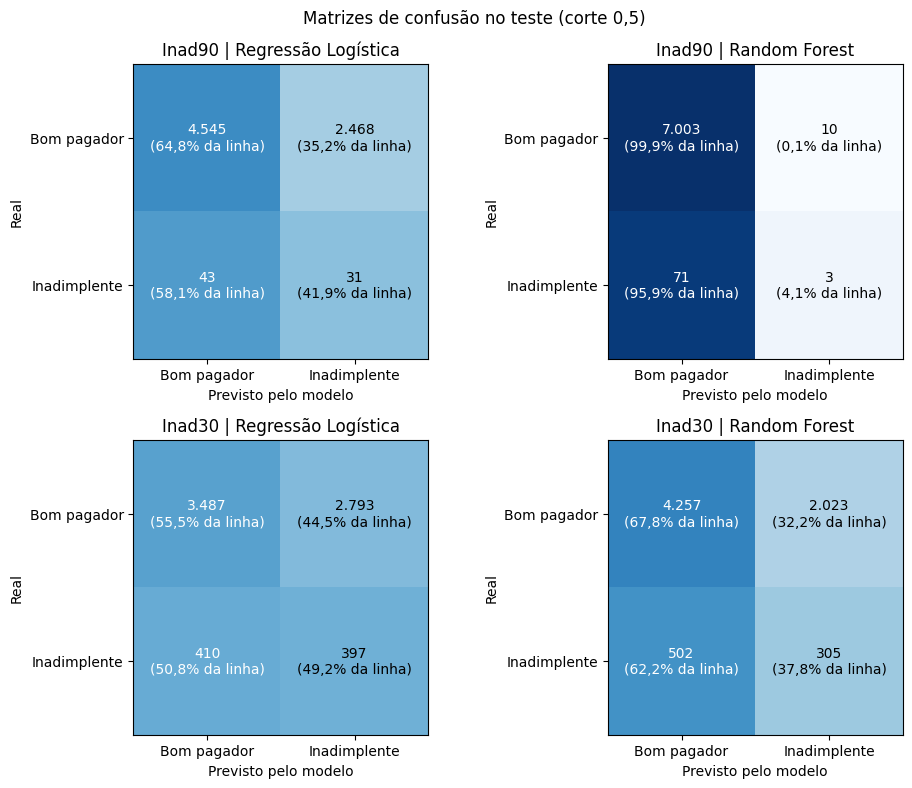

In [9]:
from sklearn.metrics import confusion_matrix

fig, eixos = plt.subplots(2, 2, figsize=(10, 8))
for i, a in enumerate(alvos):
    for j, n in enumerate(MODELOS):
        ax = eixos[i, j]
        pred = (prob_teste[(a, n)] >= CORTE_PADRAO).astype(int)
        cm = confusion_matrix(y_teste[a], pred)
        norm = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        for r in range(2):
            for c in range(2):
                ax.text(c, r, f"{br(cm[r, c])}\n({pct(norm[r, c], 1)} da linha)", ha="center", va="center",
                        color="white" if norm[r, c] > 0.5 else "black", fontsize=10)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Bom pagador", "Inadimplente"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Bom pagador", "Inadimplente"])
        ax.set_xlabel("Previsto pelo modelo"); ax.set_ylabel("Real")
        ax.set_title(f"{a} | {n}")
fig.suptitle(f"Matrizes de confusão no teste (corte {num(CORTE_PADRAO, 1)})", fontsize=12)
plt.tight_layout()
salvar(fig, "04_matrizes_confusao")
plt.show()


**Leitura do gráfico:** cada quadro mostra, para os clientes realmente bons (linha de cima) e realmente inadimplentes (linha de baixo), o que o modelo previu. Na Regressão Logística do Inad90, o corte 0,5 recusa **2.468 bons clientes (35,2% deles)** para pegar **31 dos 74 inadimplentes (41,9%)**: o custo de alarmes falsos é enorme para o ganho. No Random Forest, a coluna "Inadimplente" quase some: ele raramente aponta alguém. No Inad30, a Regressão Logística rotula como inadimplente 44,5% dos bons pagadores e 49,2% dos inadimplentes: proporções parecidas, assinatura de um modelo que **separa pouco os dois grupos**. Tudo isso mostra que o corte 0,5 não serve e que precisamos escolher o corte com critério.

## 7. Pergunta 3: qual nota de corte usar? A curva de sensibilidade ao custo

Não existe corte "certo" sem saber **quanto custa cada erro**. Chamamos de **razão de custo** quanto custa aprovar um inadimplente dividido pelo que custa recusar um bom cliente. Uma razão de 20:1, por exemplo, significa que um calote custa o mesmo que recusar 20 bons clientes. Como não conhecemos a razão real (ela depende de margem, perda média e política de crédito), **não vamos fixar uma**: mostramos o que acontece para **1, 2, 5, 10, 20, 50 e 100**.

**Como comparamos os cenários:** em relação a "aprovar todo mundo" (sem modelo), recusar um grupo de clientes **economiza** a razão multiplicada pelos inadimplentes que pegamos e **perde** um por cada bom cliente que recusamos:

`economia = razão × (inadimplentes pegos) − (bons clientes recusados)`

Se a economia é positiva, o corte compensa. Reportamos como porcentagem do custo de aprovar todos.

**Em que escala olhamos o corte:** como as probabilidades dos modelos com `class_weight` não são calibradas (o corte 0,5 não quer dizer "50% de chance"), descrevemos cada corte em linguagem de negócio: **"recusar os X% de clientes de maior risco"**, com X em 1%, 2%, 5%, 10%, 20%, 30% e 50%.

**Regra de honestidade:** a nota de corte de cada cenário é **escolhida só com o treino**, usando previsões "fora da amostra" (cada cliente é previsto por um modelo que não o viu, com perfis separados). O teste só **confere** o resultado. Escolher o corte olhando o teste seria usar o teste duas vezes e inflar o resultado.

In [10]:
from sklearn.model_selection import cross_val_predict

# Previsões "fora da amostra" no TREINO (cada cliente é previsto por um modelo que não o viu, com grupos separados).
# É com elas, e não com o teste, que escolhemos as notas de corte.
cv_oof = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
prob_oof = {
    n: cross_val_predict(montar_modelo(n, "Inad90"), X_treino, y_treino["Inad90"], cv=cv_oof,
                         groups=g_treino, method="predict_proba")[:, 1]
    for n in MODELOS
}

GRADE_RECUSA = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50]   # "recusar os X% de maior risco"
RAZOES = [1, 2, 5, 10, 20, 50, 100]                          # custo de aprovar um inadimplente / custo de recusar um bom cliente

y90_treino = y_treino["Inad90"].to_numpy()
y90_teste = y_teste["Inad90"].to_numpy()
P_TESTE = int(y90_teste.sum())

# Nota de corte (na escala da probabilidade do modelo) que equivale a recusar os X% de maior risco no treino
corte_score = {n: {q: float(np.quantile(prob_oof[n], 1 - q)) for q in GRADE_RECUSA} for n in MODELOS}

# Para cada razão de custo, qual corte da grade dá a maior economia NO TREINO?
# economia = razão x (inadimplentes pegos) - (bons clientes recusados), comparada a aprovar todo mundo
escolha = {n: {} for n in MODELOS}
for n in MODELOS:
    for r in RAZOES:
        econ = []
        for q in GRADE_RECUSA:
            c = contagens(prob_oof[n] >= corte_score[n][q], y90_treino, np.ones((1, len(y90_treino))))
            econ.append(r * c["tp"][0] - c["fp"][0])
        melhor = int(np.argmax(econ))
        escolha[n][r] = GRADE_RECUSA[melhor] if econ[melhor] > 0 else None   # None = nenhum corte compensa

linhas = [{"Razão de custo": f"{r}:1",
           **{n: ("nenhum corte compensa" if escolha[n][r] is None else f"recusar {pct(escolha[n][r], 0)} de maior risco")
              for n in MODELOS}} for r in RAZOES]
print("Corte escolhido no TREINO (previsões fora da amostra) para cada razão de custo:")
display(pd.DataFrame(linhas))


Corte escolhido no TREINO (previsões fora da amostra) para cada razão de custo:


,Razão de custo,Regressão Logística,Random Forest
0,1:1,nenhum corte compensa,nenhum corte compensa
1,2:1,nenhum corte compensa,nenhum corte compensa
2,5:1,nenhum corte compensa,nenhum corte compensa
3,10:1,nenhum corte compensa,nenhum corte compensa
4,20:1,nenhum corte compensa,recusar 1% de maior risco
5,50:1,recusar 1% de maior risco,recusar 1% de maior risco
6,100:1,recusar 10% de maior risco,recusar 5% de maior risco


**Leitura:** no treino, para razões de custo de **até 10:1, nenhum corte compensa**, nos dois modelos. A partir de 20:1 (Random Forest) e 50:1 (Regressão Logística) aparece algum corte que compensa, sempre em fatias **pequenas** de clientes (1% a 10%). O modelo só tem valor como filtro quando um calote custa **bem mais** que um bom cliente recusado.

In [11]:
def tabela_cortes(n):
    s = prob_teste[("Inad90", n)]
    linhas = []
    for q in GRADE_RECUSA:
        pred = s >= corte_score[n][q]
        obs = contagens(pred, y90_teste, PESOS_UNIT)
        boot = contagens(pred, y90_teste, PESOS)
        tp, fp = obs["tp"][0], obs["fp"][0]
        rec = divide(boot["tp"], boot["pos"])
        razao_min = np.where(boot["tp"] > 0, boot["fp"] / np.maximum(boot["tp"], 1e-9), np.nan)
        lo_r, hi_r = np.nanpercentile(razao_min, [2.5, 97.5])
        linhas.append({
            "Corte (no treino)": f"recusar {pct(q, 0)}",
            "Nota de corte": num(corte_score[n][q]),
            "Recusados no teste": pct(pred.mean()),
            "Inadimplentes pegos": f"{int(tp)} de {P_TESTE}",
            "Recall (faixa 95%)": ic_pct(tp / P_TESTE, *faixa95(rec), casas=0),
            "Bons clientes recusados": br(fp),
            "Precisão": pct(tp / max(pred.sum(), 1)),
            "Razão mínima para compensar": f"{fp / tp:.0f}:1 ({lo_r:.0f} a {hi_r:.0f})" if tp > 0 else "-",
        })
    return pd.DataFrame(linhas)


tabelas_cortes = {n: tabela_cortes(n) for n in MODELOS}
for n in MODELOS:
    print(f"\n=== {n} | Inad90 | teste: {br(len(X_teste))} clientes, {P_TESTE} inadimplentes (taxa {pct(y90_teste.mean())}) ===")
    display(tabelas_cortes[n])



=== Regressão Logística | Inad90 | teste: 7.087 clientes, 74 inadimplentes (taxa 1,04%) ===


,Corte (no treino),Nota de corte,Recusados no teste,Inadimplentes pegos,Recall (faixa 95%),Bons clientes recusados,Precisão,Razão mínima para compensar
0,recusar 1%,"0,812","0,61%",4 de 74,5% (1% a 12%),39,"9,30%",10:1 (2 a 50)
1,recusar 2%,"0,774","1,16%",6 de 74,8% (2% a 17%),76,"7,32%",13:1 (5 a 69)
2,recusar 5%,"0,714","3,61%",14 de 74,19% (6% a 35%),242,"5,47%",17:1 (9 a 56)
3,recusar 10%,"0,657","8,13%",18 de 74,24% (11% a 40%),558,"3,12%",31:1 (17 a 82)
4,recusar 20%,"0,583","17,53%",27 de 74,36% (21% a 53%),1.215,"2,17%",45:1 (28 a 94)
5,recusar 30%,"0,525","29,73%",31 de 74,42% (27% a 58%),2.076,"1,47%",67:1 (44 a 123)
6,recusar 50%,"0,439","52,87%",47 de 74,64% (48% a 77%),3.700,"1,25%",79:1 (54 a 134)



=== Random Forest | Inad90 | teste: 7.087 clientes, 74 inadimplentes (taxa 1,04%) ===


,Corte (no treino),Nota de corte,Recusados no teste,Inadimplentes pegos,Recall (faixa 95%),Bons clientes recusados,Precisão,Razão mínima para compensar
0,recusar 1%,"0,391","0,95%",5 de 74,7% (1% a 14%),62,"7,46%",12:1 (5 a 49)
1,recusar 2%,"0,334","1,89%",8 de 74,11% (3% a 21%),126,"5,97%",16:1 (7 a 61)
2,recusar 5%,"0,265","5,07%",14 de 74,19% (8% a 31%),345,"3,90%",25:1 (14 a 58)
3,recusar 10%,"0,212","12,30%",15 de 74,20% (10% a 33%),857,"1,72%",57:1 (34 a 130)
4,recusar 20%,"0,164","23,07%",28 de 74,38% (22% a 54%),1.607,"1,71%",57:1 (36 a 108)
5,recusar 30%,"0,136","33,16%",36 de 74,49% (32% a 66%),2.314,"1,53%",64:1 (44 a 113)
6,recusar 50%,"0,096","55,00%",43 de 74,58% (42% a 75%),3.855,"1,10%",90:1 (63 a 146)


**Leitura das tabelas** (teste, Inad90; a coluna "Razão mínima para compensar" é quantos bons clientes recusamos para cada inadimplente pego, ou seja, a razão de custo a partir da qual o corte passa a valer a pena):

- **Regressão Logística:** recusar os 5% de maior risco (3,61% dos clientes do teste) pega **14 dos 74 inadimplentes** e recusa **242 bons clientes**: precisão de 5,47%, mais de **5 vezes a taxa de 1,04%** do teste. A razão mínima para compensar é de **17:1** (faixa de 9 a 56). Os cortes mais estreitos são ainda mais precisos (1%: 9,30%; razão mínima de 10:1), mas pegam poucos inadimplentes (4 de 74). À medida que o corte alarga, a precisão cai e a razão mínima sobe: 31:1 em 10%, 45:1 em 20%, 67:1 em 30% e 79:1 em 50% (nesse corte pegamos 47 dos 74, ao custo de 3.700 bons clientes recusados).
- **Random Forest:** o padrão é o mesmo: razão mínima de 12:1 no corte de 1% e 25:1 em 5% (14 pegos, 345 bons recusados), subindo para 57:1 em 10% e 20%, 64:1 em 30% e 90:1 em 50%.
- **Em todos os casos, a faixa de 95% é larga**, porque o recall e a razão dependem de poucas dezenas de inadimplentes.

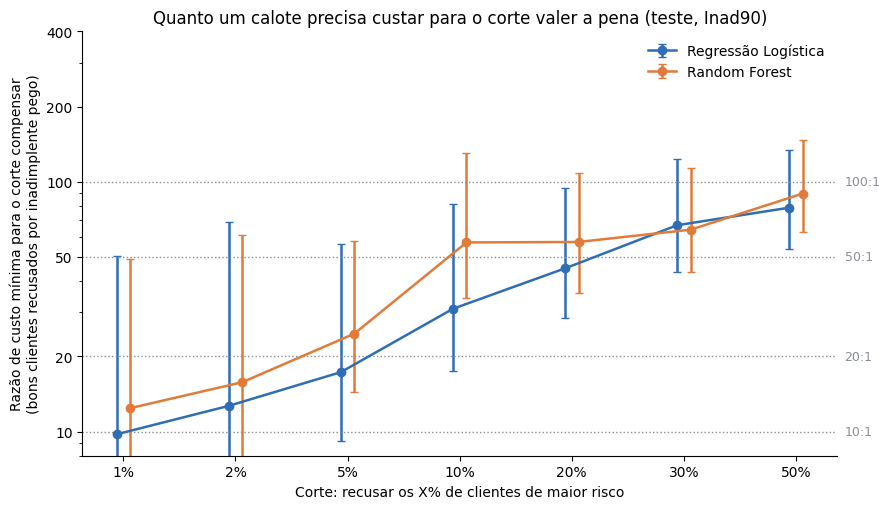

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(len(GRADE_RECUSA))
for k, n in enumerate(MODELOS):
    s = prob_teste[("Inad90", n)]
    centro, baixo, alto = [], [], []
    for q in GRADE_RECUSA:
        pred = s >= corte_score[n][q]
        obs = contagens(pred, y90_teste, PESOS_UNIT)
        boot = contagens(pred, y90_teste, PESOS)
        razao_min = np.where(boot["tp"] > 0, boot["fp"] / np.maximum(boot["tp"], 1e-9), np.nan)
        lo_r, hi_r = np.nanpercentile(razao_min, [2.5, 97.5])
        v = obs["fp"][0] / max(obs["tp"][0], 1e-9)
        centro.append(v); baixo.append(v - lo_r); alto.append(hi_r - v)
    ax.errorbar(x + (k - 0.5) * 0.12, centro, yerr=[np.maximum(baixo, 0), np.maximum(alto, 0)], marker="o",
                color=[COR_AZUL, COR_LARANJA][k], capsize=3, linewidth=1.8, label=n)
for r in [10, 20, 50, 100]:
    ax.axhline(r, color=COR_CINZA, linestyle=":", linewidth=1)
    ax.text(1.01, r, f"{r}:1", color=COR_CINZA, fontsize=9, ha="left", va="center", transform=ax.get_yaxis_transform())
ax.set_yscale("log")
ax.set_ylim(8, 400)
ax.set_yticks([10, 20, 50, 100, 200, 400]); ax.set_yticklabels([10, 20, 50, 100, 200, 400])
ax.set_xticks(x); ax.set_xticklabels([pct(q, 0) for q in GRADE_RECUSA])
ax.set_xlabel("Corte: recusar os X% de clientes de maior risco")
ax.set_ylabel("Razão de custo mínima para o corte compensar\n(bons clientes recusados por inadimplente pego)")
ax.set_title("Quanto um calote precisa custar para o corte valer a pena (teste, Inad90)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
salvar(fig, "04_razao_minima_compensar")
plt.show()


**Leitura do gráfico:** cada ponto é um corte e a altura é a **razão de custo mínima** para ele compensar (quanto menor, melhor). As linhas cinza pontilhadas são as razões que testamos. **Um corte compensa quando o ponto está abaixo da linha da razão real.** Os dois modelos têm o mesmo desenho: a curva **sobe** com a largura do corte, de cerca de 10:1 nos cortes mais estreitos a 80:1 a 90:1 nos mais largos. Se um calote custar 20 vezes um bom cliente recusado, só compensam os cortes de até 5% (Regressão Logística) ou 2% (Random Forest); com 50:1, os cortes de até 20%; com 100:1, praticamente todos. A mensagem para o negócio é que **o valor do modelo está no topo do ranking**: quanto mais estreito o corte, menor a razão de custo necessária.

In [13]:
def economia_pct(pred, r):
    """Economia líquida em relação a aprovar todo mundo, como % do custo de aprovar todo mundo."""
    obs = contagens(pred, y90_teste, PESOS_UNIT)
    boot = contagens(pred, y90_teste, PESOS)
    e_obs = (r * obs["tp"][0] - obs["fp"][0]) / (r * obs["pos"][0])
    e_boot = (r * boot["tp"] - boot["fp"]) / (r * boot["pos"])
    return e_obs, e_boot, obs


for n in MODELOS:
    s = prob_teste[("Inad90", n)]
    linhas = []
    for r in RAZOES:
        q = escolha[n][r]
        if q is None:
            linhas.append({"Razão de custo": f"{r}:1", "Corte escolhido no treino": "aprovar todos (nenhum corte compensa)",
                           "Recusados no teste": "0,00%", "Inadimplentes pegos": f"0 de {P_TESTE}",
                           "Bons clientes recusados": "0", "Economia no teste (faixa 95%)": "0,0%"})
            continue
        pred = s >= corte_score[n][q]
        e_obs, e_boot, obs = economia_pct(pred, r)
        linhas.append({"Razão de custo": f"{r}:1", "Corte escolhido no treino": f"recusar {pct(q, 0)} de maior risco",
                       "Recusados no teste": pct(pred.mean()), "Inadimplentes pegos": f"{int(obs['tp'][0])} de {P_TESTE}",
                       "Bons clientes recusados": br(obs["fp"][0]),
                       "Economia no teste (faixa 95%)": ic_pct(e_obs, *faixa95(e_boot))})
    print(f"\n=== {n} | corte escolhido no treino e resultado no teste ===")
    display(pd.DataFrame(linhas))



=== Regressão Logística | corte escolhido no treino e resultado no teste ===


,Razão de custo,Corte escolhido no treino,Recusados no teste,Inadimplentes pegos,Bons clientes recusados,Economia no teste (faixa 95%)
0,1:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
1,2:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
2,5:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
3,10:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
4,20:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
5,50:1,recusar 1% de maior risco,"0,61%",4 de 74,39,"4,4% (-0,2% a 10,8%)"
6,100:1,recusar 10% de maior risco,"8,13%",18 de 74,558,"16,8% (1,9% a 32,3%)"



=== Random Forest | corte escolhido no treino e resultado no teste ===


,Razão de custo,Corte escolhido no treino,Recusados no teste,Inadimplentes pegos,Bons clientes recusados,Economia no teste (faixa 95%)
0,1:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
1,2:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
2,5:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
3,10:1,aprovar todos (nenhum corte compensa),"0,00%",0 de 74,0,"0,0%"
4,20:1,recusar 1% de maior risco,"0,95%",5 de 74,62,"2,6% (-3,1% a 8,8%)"
5,50:1,recusar 1% de maior risco,"0,95%",5 de 74,62,"5,1% (-0,1% a 11,6%)"
6,100:1,recusar 5% de maior risco,"5,07%",14 de 74,345,"14,3% (3,8% a 26,2%)"


**Leitura das tabelas:** é o teste conferindo o corte que escolhemos no treino. Para razões de **até 20:1** (Regressão Logística) ou **10:1** (Random Forest), o corte escolhido foi "aprovar todos": economia zero. Nos cenários em que o treino mandou recusar alguém, o teste devolveu ganhos: a Regressão Logística teve **+4,4%** em 50:1 (faixa de −0,2% a 10,8%, que encosta no zero) e **+16,8%** em 100:1 (faixa de 1,9% a 32,3%, **acima de zero**); o Random Forest teve **+2,6%** em 20:1 (faixa incluindo o zero), **+5,1%** em 50:1 (−0,1% a 11,6%) e **+14,3%** em 100:1 (3,8% a 26,2%, acima de zero). Ou seja: com um calote valendo cerca de 100 bons clientes, o ganho é **claramente positivo**; em 50:1 é pequeno e incerto; em 20:1 é indistinguível de zero.

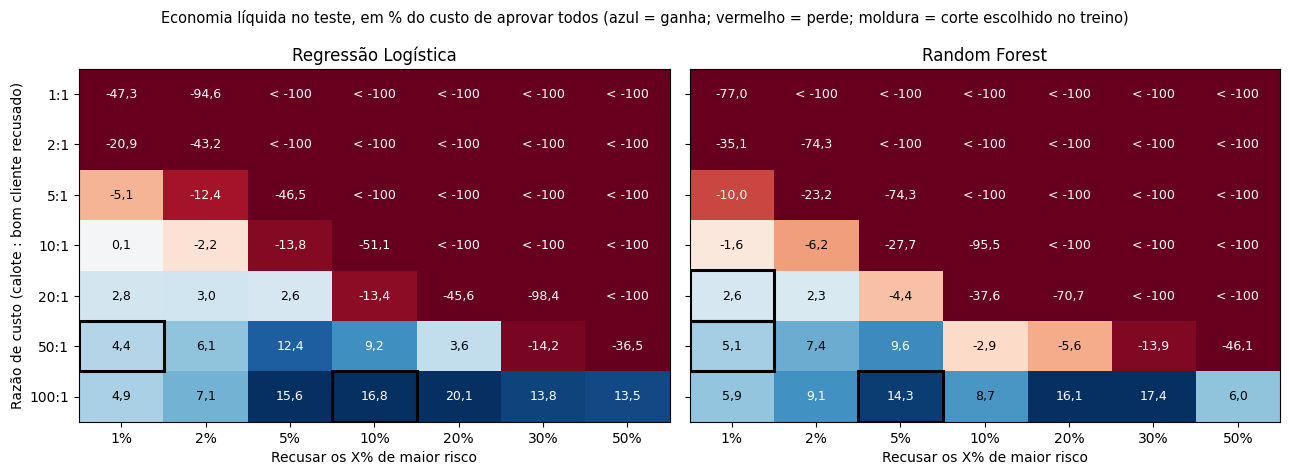

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, n in zip(eixos, MODELOS):
    s = prob_teste[("Inad90", n)]
    mat = np.zeros((len(RAZOES), len(GRADE_RECUSA)))
    for i, r in enumerate(RAZOES):
        for j, q in enumerate(GRADE_RECUSA):
            mat[i, j] = economia_pct(s >= corte_score[n][q], r)[0] * 100
    ax.imshow(np.clip(mat, -15, 15), cmap="RdBu", vmin=-15, vmax=15, aspect="auto")
    for i in range(len(RAZOES)):
        for j in range(len(GRADE_RECUSA)):
            v = mat[i, j]
            ax.text(j, i, "< -100" if v < -100 else f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=9,
                    color="white" if abs(np.clip(v, -15, 15)) > 9 else "black")
    for i, r in enumerate(RAZOES):                       # moldura = corte escolhido no treino para aquela razão
        q = escolha[n][r]
        if q is not None:
            j = GRADE_RECUSA.index(q)
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2.2))
    ax.set_xticks(range(len(GRADE_RECUSA))); ax.set_xticklabels([pct(q, 0) for q in GRADE_RECUSA])
    ax.set_yticks(range(len(RAZOES))); ax.set_yticklabels([f"{r}:1" for r in RAZOES])
    ax.set_xlabel("Recusar os X% de maior risco")
    ax.set_title(n)
eixos[0].set_ylabel("Razão de custo (calote : bom cliente recusado)")
fig.suptitle("Economia líquida no teste, em % do custo de aprovar todos (azul = ganha; vermelho = perde; moldura = corte escolhido no treino)", fontsize=10.5)
plt.tight_layout()
salvar(fig, "04_mapa_sensibilidade_custo")
plt.show()


**Leitura do gráfico:** é a **curva de sensibilidade completa**, em forma de mapa: cada linha é uma razão de custo, cada coluna é um corte e a cor é a economia no teste (azul ganha, vermelho perde; as molduras pretas marcam o corte que o treino escolheu). O canto superior direito é vermelho: para razões baixas (até 5:1) ou cortes largos, recusar clientes **destrói valor**. A região azul cresce com a razão: em 20:1 só os cortes mais estreitos (1% a 5%) ganham pouco; em 50:1 ganham os cortes de 1% a 20%; em 100:1 todos os cortes ganham. Os cortes escolhidos no treino (molduras) caíram em células azuis, perto das melhores do teste (por exemplo, 16,8% contra o máximo de 20,1% para a Regressão Logística em 100:1). Não fixamos uma razão; o que o mapa entrega é a **fronteira**: abaixo de ~10:1 o modelo não deve recusar ninguém; entre 20:1 e 50:1 só em corte muito estreito; perto de 100:1 ele já se paga em quase qualquer corte.

## 8. Pergunta 4: o que pesa na previsão?

Analisamos o Inad90 com duas técnicas complementares, uma para cada modelo, e depois comparamos:

- **Coeficientes da Regressão Logística:** o peso que cada coluna ganhou. Positivo aumenta o risco; negativo reduz. As variáveis numéricas estão normalizadas (o coeficiente vale para uma variação de 1 desvio-padrão) e as categorias estão em 0/1, então os pesos são comparáveis entre si. Mostramos também quantos clientes e quantos inadimplentes há em cada categoria, para saber se o peso tem base.
- **Importância por permutação (nos dois modelos):** embaralhamos uma variável do teste e medimos quanto a AUC-ROC cai. Se cai muito, o modelo dependia dela. Fazemos isso sobre as **17 variáveis originais**, não sobre as 46 colunas do *one-hot*, para ler "estado civil" como um todo.

,Variável,Coeficiente,Clientes no treino,Inad90 no treino
0,Desempregado ou aposentado,"-4,13",-,-
1,Ocupação: Private service staff,"-3,65",297,0
2,Escolaridade: categorias raras,"-1,39",-,-
3,Tipo de renda: categorias raras,"-1,14",-,-
4,Moradia: With parents,"-1,13",1.400,5
5,Ocupação: Cleaning staff,"-0,94",479,1
6,Tipo de renda: State servant,"-0,94",2.333,15
7,Estado civil: Civil marriage,"-0,87",2.277,6
8,Tipo de renda: Working,"-0,66",15.185,106
9,Ocupação: Managers,"-0,48",2.481,9


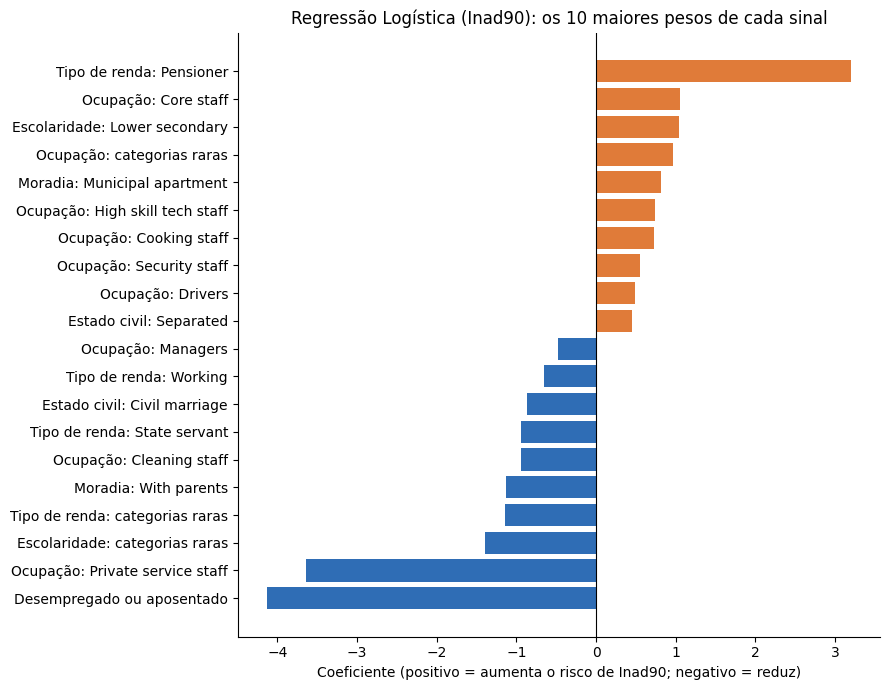

Efeito líquido de ser Pensioner: 3,20 + -4,13 = -0,93
Pensioners que também são 'Desempregado ou aposentado': 99,72%


In [15]:
ROTULOS = {
    "CODE_GENDER": "Sexo", "FLAG_OWN_CAR": "Possui carro", "FLAG_OWN_REALTY": "Possui imóvel",
    "CNT_CHILDREN": "Nº de filhos", "AMT_INCOME_TOTAL": "Renda (log)", "NAME_INCOME_TYPE": "Tipo de renda",
    "NAME_EDUCATION_TYPE": "Escolaridade", "NAME_FAMILY_STATUS": "Estado civil", "NAME_HOUSING_TYPE": "Moradia",
    "FLAG_WORK_PHONE": "Telefone do trabalho", "FLAG_PHONE": "Telefone", "FLAG_EMAIL": "E-mail",
    "OCCUPATION_TYPE": "Ocupação", "CNT_FAM_MEMBERS": "Membros da família", "Idade": "Idade",
    "Desempregado ou aposentado": "Desempregado ou aposentado", "Anos_Trabalhados": "Anos trabalhados",
}
CATEGORIAS = {"Y": "sim", "M": "masculino", "infrequent_sklearn": "categorias raras"}


def rotulo(nome):
    """Nome legível para uma coluna (original ou criada pelo one-hot)."""
    if nome in ROTULOS:
        return ROTULOS[nome]
    for col, rot in ROTULOS.items():
        if nome.startswith(col + "_"):
            cat = nome[len(col) + 1:]
            return f"{rot}: {CATEGORIAS.get(cat, cat)}"
    return nome


rl90 = modelos_finais[("Inad90", "Regressão Logística")]
nomes = rl90.named_steps["prep"].get_feature_names_out()
coef = pd.Series(rl90.named_steps["modelo"].coef_[0], index=nomes)

# Quantos clientes e quantos Inad90 há em cada categoria (para saber se o coeficiente tem base)
def casos_da_variavel(nome):
    if nome in X_treino.columns:
        return np.nan, np.nan
    for col in colunas_cat:
        if nome.startswith(col + "_"):
            cat = nome[len(col) + 1:]
            if cat == "infrequent_sklearn":
                return np.nan, np.nan
            cat = {"Y": "Y", "M": "M"}.get(cat, cat)
            m = X_treino[col] == cat
            return int(m.sum()), int(y_treino["Inad90"][m].sum())
    return np.nan, np.nan


top = pd.concat([coef.sort_values().head(10), coef.sort_values().tail(10)])
tab = pd.DataFrame({
    "Variável": [rotulo(v) for v in top.index],
    "Coeficiente": [num(c, 2) for c in top.values],
    "Clientes no treino": [("-" if np.isnan(casos_da_variavel(v)[0]) else br(casos_da_variavel(v)[0])) for v in top.index],
    "Inad90 no treino": [("-" if np.isnan(casos_da_variavel(v)[1]) else br(casos_da_variavel(v)[1])) for v in top.index],
}).reset_index(drop=True)
display(tab)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([rotulo(v) for v in top.index], top.values, color=[COR_LARANJA if c > 0 else COR_AZUL for c in top.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (positivo = aumenta o risco de Inad90; negativo = reduz)")
ax.set_title("Regressão Logística (Inad90): os 10 maiores pesos de cada sinal")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
salvar(fig, "04_coeficientes_regressao_logistica")
plt.show()

efeito_liquido = coef["NAME_INCOME_TYPE_Pensioner"] + coef["Desempregado ou aposentado"]
print(f"Efeito líquido de ser Pensioner: {num(coef['NAME_INCOME_TYPE_Pensioner'], 2)} + {num(coef['Desempregado ou aposentado'], 2)} = {num(efeito_liquido, 2)}")
print("Pensioners que também são 'Desempregado ou aposentado':",
      pct(((base['NAME_INCOME_TYPE'] == 'Pensioner') & (base['Desempregado ou aposentado'])).sum() / (base['NAME_INCOME_TYPE'] == 'Pensioner').sum()))


**Leitura:** os pesos que mais chamam a atenção precisam de cuidado antes de qualquer interpretação:

- **`Tipo de renda: Pensioner` (+3,20) e `Desempregado ou aposentado` (−4,13)** são duas formas de dizer quase a mesma coisa: **99,72% dos aposentados do tipo de renda também estão marcados como "Desempregado ou aposentado"**. Os dois pesos enormes e opostos se anulam: o efeito líquido de ser aposentado é de **−0,93**, da mesma ordem dos demais tipos de renda (`Working` −0,66, `State servant` −0,94). A leitura correta não é "aposentado é o maior risco", e sim "essas duas colunas duplicam a informação e a Regressão Logística as dividiu de forma instável".
- **`Ocupação: Private service staff` (−3,65)** parece o maior fator de proteção, mas foi aprendido com **297 clientes e 0 inadimplentes** no treino: é ausência de casos, não prova de segurança. O mesmo vale para os grupos de **categorias raras**, que reúnem pouquíssimos clientes.
- **Sinais com base mais razoável:** `Ocupação: Core staff` (+1,05; 2.863 clientes, 38 inadimplentes), `Moradia: Municipal apartment` (+0,81; 875 clientes, 15 inadimplentes) e `Escolaridade: Lower secondary` (+1,04; 322 clientes) como sinais de maior risco, e `Moradia: With parents` (−1,13) e `Estado civil: Civil marriage` (−0,87; 2.277 clientes, 6 inadimplentes) como sinais de menor risco. São relações plausíveis (moradia e estabilidade familiar), mas **não são causais** e os pesos têm pouca base de casos.
- **A renda declarada praticamente não pesa** (coeficiente de 0,05, quase nulo). Para um analista de crédito isso é um achado: a renda informada no cadastro não distingue quem vai atrasar.

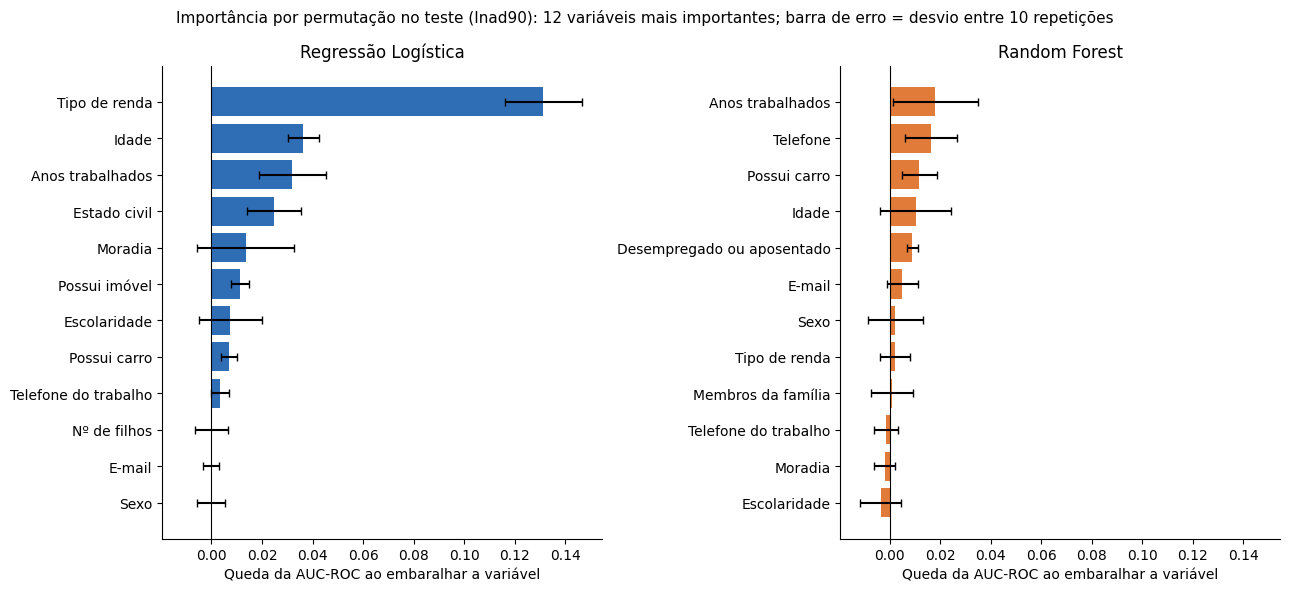

Posição de cada variável nos dois rankings (1 = mais importante) e queda média da AUC-ROC (desvio entre 10 repetições):


,Regressão Logística: posição,Regressão Logística: queda da AUC-ROC (desvio),Random Forest: posição,Random Forest: queda da AUC-ROC (desvio),Soma das posições
Anos trabalhados,3,"0,032 (0,013)",1,"0,018 (0,017)",4
Idade,2,"0,036 (0,006)",4,"0,010 (0,014)",6
Tipo de renda,1,"0,131 (0,015)",8,"0,002 (0,006)",9
Possui carro,8,"0,007 (0,003)",3,"0,012 (0,007)",11
Telefone,13,"-0,001 (0,001)",2,"0,016 (0,010)",15
Moradia,5,"0,014 (0,019)",11,"-0,002 (0,004)",16
E-mail,11,"-0,000 (0,003)",6,"0,005 (0,006)",17
Possui imóvel,6,"0,011 (0,004)",13,"-0,006 (0,006)",19


Renda (log): coeficiente da Regressão Logística = 0,05; queda da AUC-ROC na permutação = -0,003 (RL) e -0,019 (RF)
Estado civil e Sexo (queda da AUC-ROC, RL | RF): {'Estado civil': '0,025 | -0,015', 'Sexo': '-0,000 | 0,002'}


In [16]:
from sklearn.inspection import permutation_importance

# Importância por permutação, na variável ORIGINAL (17 variáveis, não as 46 colunas do one-hot):
# embaralhamos uma variável do teste e medimos quanto a AUC-ROC cai.
imp = {}
for n in MODELOS:
    r = permutation_importance(modelos_finais[("Inad90", n)], X_teste, y_teste["Inad90"], scoring="roc_auc",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
    imp[n] = pd.DataFrame({"media": r.importances_mean, "desvio": r.importances_std}, index=X_teste.columns)

fig, eixos = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
for ax, n, cor in zip(eixos, MODELOS, [COR_AZUL, COR_LARANJA]):
    d = imp[n].sort_values("media").tail(12)
    ax.barh([rotulo(v) for v in d.index], d["media"], xerr=d["desvio"], color=cor, capsize=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(n)
    ax.set_xlabel("Queda da AUC-ROC ao embaralhar a variável")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Importância por permutação no teste (Inad90): 12 variáveis mais importantes; barra de erro = desvio entre 10 repetições", fontsize=11)
plt.tight_layout()
salvar(fig, "04_importancia_permutacao")
plt.show()

pos = {n: imp[n]["media"].rank(ascending=False).astype(int) for n in MODELOS}
ranking = pd.DataFrame(index=imp[MODELOS[0]].index)
for n in MODELOS:
    ranking[f"{n}: posição"] = pos[n]
    ranking[f"{n}: queda da AUC-ROC (desvio)"] = [f"{num(m, 3)} ({num(d, 3)})" for m, d in zip(imp[n]["media"], imp[n]["desvio"])]
ranking["Soma das posições"] = sum(pos[n] for n in MODELOS)
ranking.index = [rotulo(v) for v in ranking.index]
print("Posição de cada variável nos dois rankings (1 = mais importante) e queda média da AUC-ROC (desvio entre 10 repetições):")
display(ranking.sort_values("Soma das posições").head(8))
print(f"Renda (log): coeficiente da Regressão Logística = {num(coef['AMT_INCOME_TOTAL'], 2)}; queda da AUC-ROC na permutação = "
      f"{num(imp['Regressão Logística'].loc['AMT_INCOME_TOTAL', 'media'], 3)} (RL) e {num(imp['Random Forest'].loc['AMT_INCOME_TOTAL', 'media'], 3)} (RF)")
print("Estado civil e Sexo (queda da AUC-ROC, RL | RF):",
      {rotulo(v): f"{num(imp['Regressão Logística'].loc[v, 'media'], 3)} | {num(imp['Random Forest'].loc[v, 'media'], 3)}" for v in ["NAME_FAMILY_STATUS", "CODE_GENDER"]})


**Leitura:** a importância por permutação mede o quanto cada variável contribui para ordenar bem **no teste**. Os dois modelos concordam em duas variáveis: **`Anos trabalhados` (3ª posição na Regressão Logística e 1ª no Random Forest) e `Idade` (2ª e 4ª)** estão no topo dos dois rankings. Fora isso, eles divergem: a Regressão Logística valoriza muito `Tipo de renda` (queda de 0,131 na AUC-ROC) e `Estado civil` (0,025), e o Random Forest valoriza `Telefone` e `Possui carro`; `Estado civil` não pesa nele (−0,015).

Quatro cuidados para ler o gráfico:

1. **O peso de `Tipo de renda` na Regressão Logística está inflado.** Como vimos nos coeficientes, ele forma um par redundante com `Desempregado ou aposentado`: embaralhar uma das duas desfaz o cancelamento entre elas e derruba o modelo, o que não significa que o tipo de renda seja um sinal forte por si só.
2. **As demais quedas são pequenas** (de 0,01 a 0,04 de AUC-ROC): nenhuma variável sozinha carrega o modelo, coerente com um sinal global fraco.
3. **Várias variáveis ficam em torno de zero ou abaixo**, entre elas a **renda** (queda de −0,003 na Regressão Logística e −0,019 no Random Forest): o modelo não precisa dela.
4. **Só 74 inadimplentes.** A barra de erro mostra apenas a variação do embaralhamento, não a incerteza da amostra; a ordem exata do ranking não é confiável, apenas os grandes blocos.

**Faz sentido de negócio?** Em parte: tempo de trabalho (estabilidade de renda) e idade são sinais clássicos em risco de crédito. Um ponto de atenção para Jurídico e Compliance: **`Idade` e `Estado civil` pesam no modelo (e `Sexo` está entre as variáveis usadas, ainda que sem peso relevante)**. Usar atributos pessoais desse tipo em decisão de crédito exige análise de conformidade e de equidade antes de qualquer uso real.

## 9. Pergunta 5 (parte 1): qual modelo escolhemos?

No notebook 3, os dois modelos empataram na validação cruzada. Para desempatar, usamos o que o teste nos oferece: comparamos os dois **nas mesmas reamostragens de perfis** (comparação pareada). Assim, a diferença entre eles tem uma faixa de incerteza própria, e vemos se o zero (empate) está dentro dela.

In [17]:
linhas = []
for a in alvos:
    for metrica in ("AUC-PR", "AUC-ROC"):
        rl_obs, rl_boot = auc[(a, "Regressão Logística")][metrica]
        rf_obs, rf_boot = auc[(a, "Random Forest")][metrica]
        dif = rl_boot - rf_boot
        lo, hi = faixa95(dif)
        linhas.append({
            "Target": a, "Métrica": metrica,
            "Reg. Logística": num(rl_obs), "Random Forest": num(rf_obs),
            "Diferença RL - RF (faixa 95%)": ic(rl_obs - rf_obs, lo, hi),
            "Chance de a RL ser melhor": pct((dif > 0).mean(), 0),
            "Faixa inclui zero?": "Sim (empate)" if lo <= 0 <= hi else "Não",
        })
print("Comparação pareada no teste: os dois modelos são avaliados nas MESMAS reamostragens de perfis.")
display(pd.DataFrame(linhas))


Comparação pareada no teste: os dois modelos são avaliados nas MESMAS reamostragens de perfis.


,Target,Métrica,Reg. Logística,Random Forest,Diferença RL - RF (faixa 95%),Chance de a RL ser melhor,Faixa inclui zero?
0,Inad90,AUC-PR,"0,039","0,043","-0,003 (-0,050 a 0,041)",48%,Sim (empate)
1,Inad90,AUC-ROC,"0,599","0,577","0,022 (-0,099 a 0,152)",61%,Sim (empate)
2,Inad30,AUC-PR,"0,142","0,134","0,008 (-0,009 a 0,031)",81%,Sim (empate)
3,Inad30,AUC-ROC,"0,554","0,545","0,009 (-0,017 a 0,035)",74%,Sim (empate)


**Leitura da tabela:** **a faixa de 95% da diferença inclui o zero em todas as comparações**, nos dois targets e nas duas métricas. A Regressão Logística tem AUC-ROC melhor no Inad90 (0,599 contra 0,577), o Random Forest tem AUC-PR um pouco melhor (0,043 contra 0,039), e a chance de a Regressão Logística ser a melhor fica entre 48% e 81% conforme a métrica: **é um empate técnico, de novo**, agora confirmado no teste. Na análise de custo (seção 7), os dois modelos também têm comportamento parecido.

**Decisão: Regressão Logística, no Inad90.** Como o desempenho não separa os modelos, desempatamos por critérios de negócio:

1. **Interpretabilidade:** cada variável tem um peso que a área de risco consegue ler, questionar e auditar (inclusive para identificar variáveis sensíveis, como vimos na seção 8). A Random Forest é uma "caixa mais fechada".
2. **Estabilidade e simplicidade:** é mais barata de manter, mais rápida e menos sujeita a decorar casos raros.
3. **Nenhum ganho do modelo mais complexo:** quando a complexidade não compra desempenho, ficamos com o modelo mais simples.

Mantemos o **Inad90 como target principal**. O Inad30 tem sinal detectável (AUC-ROC de 0,554 e 0,545), mas sem utilidade prática: a precisão (12,4% a 13,1%) mal supera a taxa de base (11,4%).

## 10. Pergunta 5 (parte 2): como esse modelo deve ser usado? Implicações de negócio

Traduzimos o resultado da Regressão Logística no Inad90 para um cenário concreto: **a cada 1.000 clientes novos**, o que acontece em cada corte? A taxa de inadimplência no teste é de 1,04%, ou seja, cerca de **10 inadimplentes** em 1.000 clientes.

In [18]:
# Modelo escolhido: Regressão Logística, Inad90. Tradução para "a cada 1.000 clientes novos".
n_esc = "Regressão Logística"
s = prob_teste[("Inad90", n_esc)]
prev = y90_teste.mean()
linhas = []
for q in [0.02, 0.05, 0.10, 0.20]:
    pred = s >= corte_score[n_esc][q]
    c = contagens(pred, y90_teste, PESOS_UNIT)
    por_mil = 1000 / c["n"][0]
    apontados = pred.sum() * por_mil
    linhas.append({
        "Corte": f"recusar {pct(q, 0)} de maior risco",
        "Clientes apontados": f"{apontados:.0f}",
        "Inadimplentes entre os apontados": f"{c['tp'][0] * por_mil:.1f}".replace(".", ","),
        "Esperado sem o modelo (sorteio)": f"{apontados * prev:.1f}".replace(".", ","),
        "Bons clientes apontados": f"{c['fp'][0] * por_mil:.0f}",
        "Inadimplentes que passam": f"{c['fn'][0] * por_mil:.1f}".replace(".", ","),
    })
print(f"A cada 1.000 clientes novos (taxa de Inad90 de {pct(prev)}, ou seja, cerca de {num(prev * 1000, 1)} inadimplentes), Regressão Logística:")
display(pd.DataFrame(linhas))


A cada 1.000 clientes novos (taxa de Inad90 de 1,04%, ou seja, cerca de 10,4 inadimplentes), Regressão Logística:


,Corte,Clientes apontados,Inadimplentes entre os apontados,Esperado sem o modelo (sorteio),Bons clientes apontados,Inadimplentes que passam
0,recusar 2% de maior risco,12,"0,8","0,1",11,"9,6"
1,recusar 5% de maior risco,36,"2,0","0,4",34,"8,5"
2,recusar 10% de maior risco,81,"2,5","0,8",79,"7,9"
3,recusar 20% de maior risco,175,"3,8","1,8",171,"6,6"


### O que a tabela mostra

No corte de **5% de maior risco**, o modelo aponta **36 clientes** a cada 1.000. Entre eles, esperamos **2,0 inadimplentes**, contra 0,4 se escolhêssemos 36 clientes ao acaso: o modelo **multiplica a taxa de acerto por 5**. Mas, ao mesmo tempo, **34 dos 36 apontados são bons clientes**, e **8,5 dos 10,4 inadimplentes passam sem ser apontados**. É um ganho real, concentrado no topo do ranking, mas pequeno em volume: o modelo ajuda a **priorizar**, não a **decidir**. Cortes mais largos pegam mais inadimplentes (6,6 passam no corte de 20%), mas ao custo de recusar 171 bons clientes.

### O que recomendamos

1. **Não usar o modelo como decisor único.** Como filtro de recusa, ele só compensa se um calote custar bem mais que um bom cliente recusado: em torno de **20 vezes** nos cortes mais estreitos (até 5%), de **50 vezes** nos cortes de até 20% e perto de **100 vezes** para cortes largos (seção 7). Sem conhecer essa razão, recusar automaticamente seria uma aposta.
2. **Usar como apoio de triagem.** O modelo ordena os pedidos por risco; os **5% a 10% de maior risco** seguem para uma análise adicional (documentação, limite inicial mais baixo ou garantia), enquanto o resto segue o fluxo normal. Nesse uso, um falso alarme não custa "um cliente perdido", custa **uma análise a mais**, o que baixa muito a razão de custo relevante e leva o modelo para a região em que compensa.
3. **Aplicar só ao atraso grave (Inad90).** Para o atraso leve (Inad30), o cadastro praticamente não prevê nada.
4. **Antes de operar:** (a) estimar com Risco e Finanças a razão de custo real; (b) calibrar as probabilidades (os modelos com `class_weight` não dão "chance real"); (c) revisar com Jurídico e Compliance o uso de variáveis como idade, estado civil e sexo; (d) começar com um piloto e **medir de verdade** o que acontece com os clientes sinalizados.
5. **O caminho para melhorar não é um algoritmo mais sofisticado.** Dois algoritmos bem diferentes chegaram ao mesmo ponto: o limite está na **informação do cadastro**. Ganho relevante exigiria dados mais ricos (comportamento de pagamento, consulta a bureau de crédito, renda comprovada).

### Limitações

- **Base restrita:** só 8,31% do cadastro (36.457 de 438.463 clientes) tem histórico de crédito. Aprendemos com quem já foi aprovado e tem histórico; não sabemos como se comportariam os clientes que não entraram.
- **Efeito de exposição:** quem tem mais meses de histórico tem mais chances de atrasar em algum mês. Retiramos `MESES_HISTORICO` das variáveis, mas o target ("algum atraso") continua misturando risco e tempo de observação.
- **Poucos positivos:** 74 inadimplentes no teste (Inad90). Por isso, todas as faixas são largas, e várias conclusões (corte ideal, ranking de variáveis) são **direcionais**, não precisas.
- **Dependência da divisão:** como o conteúdo do teste muda com a versão da biblioteca (e, portanto, com a divisão sorteada), os números exatos variam de uma divisão para outra. A conclusão qualitativa (sinal fraco, valor concentrado no topo do ranking) é o que se mantém.
- **Perfis repetidos:** cerca de 96% dos clientes dividem perfil com outros. A divisão por perfil e o bootstrap por perfil tratam disso, mas a quantidade efetiva de informação independente é menor que o número de clientes.
- **Sem validação no tempo:** dividimos por perfil, não por data. Não sabemos se o desempenho se mantém quando o comportamento dos clientes muda.
- **Razão de custo desconhecida:** a curva de sensibilidade mostra os cenários, mas a decisão final depende de números que só o negócio tem.

## 11. Respostas às perguntas e conclusão do projeto

### Respostas

**1. O cadastro prevê inadimplência em clientes novos?** **Só em parte, e de forma fraca.** No teste, a AUC-ROC do atraso grave (Inad90) é de 0,599 (Regressão Logística) e 0,577 (Random Forest): acima do sorteio, mas com faixas (de 0,502 a 0,692 e de 0,468 a 0,684) que encostam ou incluem 0,5. No atraso leve (Inad30), a AUC-ROC é de 0,554 e 0,545: sinal detectável, mas sem valor prático. O teste **confirmou** o que o notebook 3 havia encontrado.

**2. Quais métricas contam a verdade?** **AUC-PR e AUC-ROC** para comparar modelos sem depender de corte, e **recall, precisão e matriz de confusão** (com faixa de incerteza) para entender o custo de cada erro. A **acurácia engana**: "aprovar todo mundo" acerta 98,96% no Inad90 sem prever nada, mais que o Random Forest (98,9%), que pega apenas 3 dos 74 inadimplentes.

**3. Qual nota de corte usar?** **Depende do custo do erro, e não fixamos uma razão.** Para razões de até 10:1, nenhum corte compensa. O modelo se paga em cortes **estreitos** (5% a 10% de maior risco) a partir de uns 20 a 50 vezes, e em quase qualquer corte perto de 100 vezes o custo de um bom cliente recusado; com 100:1, o ganho no teste é claramente positivo (+16,8% na Regressão Logística, com faixa de 1,9% a 32,3%). O corte deve ser escolhido no treino.

**4. O que pesa na previsão?** **Tempo de trabalho e idade** aparecem no topo dos dois modelos; a Regressão Logística também valoriza tipo de renda (inflado por uma coluna redundante) e estado civil. A renda declarada praticamente não pesa, as quedas de desempenho são pequenas e várias colunas são redundantes ou têm poucos casos. Idade, estado civil e sexo exigem revisão de conformidade antes de uso real.

**5. Qual modelo levamos e como usá-lo?** A **Regressão Logística no Inad90**, por empate técnico com o Random Forest no teste e maior interpretabilidade. Seu papel é **apoio de triagem** (priorizar análises), e **não decisor único**: no corte de 5%, o modelo multiplica a taxa de acerto por 5 (5,47% contra 1,04%), mas 34 de cada 36 clientes apontados são bons pagadores.

### Conclusão do projeto

Partimos de uma pergunta de negócio: dá para prever, só com o que o cliente declara no cadastro, quem vai ficar inadimplente? Tratamos os dados e entendemos a base (notebook 1), definimos a inadimplência com dois critérios e provamos que o histórico mais longo não podia entrar no modelo (notebook 2), comparamos dois modelos sem vazamento, separando perfis idênticos (notebook 3), e agora confirmamos tudo em clientes que os modelos nunca viram (notebook 4).

**A resposta é: um pouco, e não o bastante para decidir sozinho.** O cadastro tem um sinal fraco no conjunto, com valor concentrado no topo do ranking (os 5% de maior risco têm cerca de 5 vezes a taxa média de inadimplência), e quase nenhum sinal para o atraso leve. Isso vale para dois algoritmos bem diferentes, então o limite está na **informação disponível**, não na técnica. Um modelo assim serve como **apoio de triagem** para organizar a fila de análise, não como juiz de aprovação ou recusa. Se a instituição quiser crédito automatizado de verdade, o investimento certo é em **mais e melhores dados**.

### Resumo

**O que fizemos**

- Recriamos os modelos do notebook 3 e os avaliamos **uma única vez** no teste (7.087 clientes, 74 inadimplentes no Inad90), com bootstrap por perfil.
- Mostramos por que a acurácia engana e comparamos AUC-PR, AUC-ROC, recall, precisão, F1 e matrizes de confusão.
- Escolhemos o corte pelo custo de negócio como **curva de sensibilidade** (razões de 1:1 a 100:1), selecionando no treino e conferindo no teste.
- Analisamos a importância das variáveis por coeficientes e por permutação, e escolhemos a Regressão Logística.

**O que encontramos**

- Sinal **fraco** no Inad90 (AUC-ROC de 0,58 a 0,60, com faixas que encostam no sorteio) e **muito fraco** no Inad30 (0,55).
- O valor está no **topo do ranking**: no corte de 5%, a taxa de acerto é 5 vezes a média (5,47% contra 1,04%), mas 34 em cada 36 apontados são bons clientes.
- Como filtro de recusa, o modelo só compensa se o calote custar bem mais que um bom cliente recusado (de ~20 a ~100 vezes, conforme a largura do corte); abaixo de 10:1, nenhum corte vale a pena.

**Em uma frase:** o cadastro **ajuda a priorizar quem olhar com mais atenção**, mas não é suficiente para dizer sozinho quem deve ou não receber crédito.